# IMAGO | Sentinel-3 Land Surface Temperature Indicators

**Data:** IMAGO Sentinel-3 Seasonal Land Surface Temperature (LST) Indicators per MSOA, UK, 2019–2024.

**Goal:** Explore the IMAGO LST product and understand the distribution and spatial patterns of summer daytime and night-time LST.

> **Getting the data**
>
> IMAGO produces seasonal LST indicators for summer (June–August) and winter (December–February), using Sentinel-3 observations accessed through the [Earth Observation DataHub (EODH)](https://eodatahub.org.uk/).
>
> This tutorial focuses on the summer daytime and night-time products for 2019–2024.
>
> The datasets will be available through the [IMAGO Data Catalogue](https://data.imago.ac.uk/) following their release.
>
> The data are organised into two folders:
>
> - `summer_day/`: Summer daytime LST indicators for 2019–2024.
> - `summer_night/`: Summer night-time LST indicators for 2019–2024.
>
> Each folder contains annual datasets in CSV and GeoPackage formats, together with accompanying metadata describing the indicators, data structure and processing.
>
> Save the downloaded files in `data/lst_sentinel3/` in your project, retaining the original filenames and folder structure.
>
> <span style="color:#1565C0;"><strong>Note: If the data are already provided in your workspace, there is no need to download them again.</strong></span>

> **Product status**
>
> This tutorial uses the first version of the IMAGO Sentinel-3 LST product, provided for educational and exploratory research purposes. Further quality assessment, methodological refinement and validation are ongoing. Users should consider observation coverage, gap-filled values and quality flags when interpreting the results.

## What is Land Surface Temperature?

LST describes the temperature of the Earth's surface, as measured using thermal infrared satellite observations. Unlike air temperature, LST represents the temperature of surfaces such as vegetation, buildings, roads and bare soil.

The IMAGO product uses observations from the Sentinel-3 Sea and Land Surface Temperature Radiometer (SLSTR) at approximately 1 km spatial resolution to derive seasonal temperature indicators. The summer product includes mean, median, 90th percentile and maximum LST.

These indicators are aggregated to MSOA-equivalent geographies across the UK. The resulting datasets provide area-level seasonal temperature indicators rather than individual satellite pixel values.

## The Reason for the Data

LST indicators support research into urban environments, geographical variations in surface heating and climate adaptation. Daytime and night-time observations provide complementary information about surface thermal conditions.

Providing these indicators at standard statistical geographies facilitates integration with population, housing, greenspace, health and other environmental datasets. However, area-level LST indicators do not resolve street-level temperature variation or directly measure personal heat exposure.

## Installing Libraries

We use GeoPandas for spatial data, pandas for tabular data, NumPy for numerical operations and Matplotlib for visualisation.

If these packages are not installed, run `%pip install geopandas pandas numpy matplotlib` in a separate cell.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

## Loading the Datasets
For this tutorial, we use the 2024 summer daytime and night-time datasets as an example. Users can select another available year to explore the corresponding seasonal LST indicators.

In [2]:
roots = [Path("../data/lst_sentinel3"), Path("data/lst_sentinel3")]
data_dir = next((p for p in roots if p.is_dir()), roots[0])

files = {}

for period in ("day", "night"):
    for path in sorted((data_dir / f"summer_{period}").glob("*.gpkg")):
        match = re.search(r"(?<!\d)(2019|2020|2021|2022|2023|2024)(?!\d)", path.name)
        if match:
            files.setdefault((period, int(match.group())), []).append(path)

inventory = pd.DataFrame({
    period: [len(files.get((period, y), [])) for y in range(2019, 2025)]
    for period in ("day", "night")
}, index=pd.Index(range(2019, 2025), name="Year"))

print("GeoPackages found per year:")
display(inventory)

GeoPackages found per year:


,day,night
Year,,
2019,1,1
2020,1,1
2021,1,1
2022,1,1
2023,1,1
2024,1,1


In [3]:
year = 2024  # Change to any year with both files available

def load_lst(period, selected_year):
    candidates = files.get((period, selected_year), [])
    if len(candidates) != 1:
        raise ValueError(f"Expected one {period} GeoPackage for {selected_year}; found {candidates}. Check the inventory and retain one intended version.")
    print("Loading:", candidates[0].name)
    return gpd.read_file(candidates[0])

day = load_lst("day", year)
night = load_lst("night", year)
display(day.head())
display(night.head())

Loading: UK_datazones_2024_summer_day_lst_msoa_v1.gpkg
Loading: UK_datazones_2024_summer_night_lst_msoa_v1.gpkg


,data_zone_code,data_zone_name,year,season,lst_mean,lst_median,lst_p90,lst_max,valid_count,coverage_pct,filled_pct,quality_flag,geometry
0,E02000001,City of London 001,2024,summer,32.0579,31.1674,37.3033,38.7398,31,34.9270,0.0,NaN,"MULTIPOLYGON (((532135.138 182198.131, 532158...."
1,E02000002,Barking and Dagenham 001,2024,summer,29.8124,29.2645,35.4306,37.7801,36,38.7616,0.0,NaN,"MULTIPOLYGON (((548881.563 190845.265, 548881...."
2,E02000003,Barking and Dagenham 002,2024,summer,32.8413,32.2577,38.3365,39.8855,36,39.0737,0.0,NaN,"MULTIPOLYGON (((549102.438 189324.625, 548954...."
3,E02000004,Barking and Dagenham 003,2024,summer,31.5552,31.3511,36.9559,38.2836,38,42.6573,0.0,NaN,"MULTIPOLYGON (((551550.056 187364.705, 551478 ..."
4,E02000005,Barking and Dagenham 004,2024,summer,33.5831,32.9353,39.1627,40.8894,38,41.4739,0.0,NaN,"MULTIPOLYGON (((549099.634 187656.076, 549161...."


,data_zone_code,data_zone_name,year,season,lst_mean,lst_median,lst_p90,lst_max,valid_count,coverage_pct,filled_pct,quality_flag,geometry
0,E02000001,City of London 001,2024,summer,18.5773,18.3955,22.6946,24.1075,52,56.4648,0.0,NaN,"MULTIPOLYGON (((532135.138 182198.131, 532158...."
1,E02000002,Barking and Dagenham 001,2024,summer,16.4603,16.3903,20.1600,23.0244,47,50.2457,0.0,NaN,"MULTIPOLYGON (((548881.563 190845.265, 548881...."
2,E02000003,Barking and Dagenham 002,2024,summer,17.0076,16.8183,20.4272,23.4259,47,51.6739,0.0,NaN,"MULTIPOLYGON (((549102.438 189324.625, 548954...."
3,E02000004,Barking and Dagenham 003,2024,summer,17.1388,16.8550,20.7263,23.3477,45,49.0471,0.0,NaN,"MULTIPOLYGON (((551550.056 187364.705, 551478 ..."
4,E02000005,Barking and Dagenham 004,2024,summer,17.5837,17.4085,21.0981,23.6869,49,53.3348,0.0,NaN,"MULTIPOLYGON (((549099.634 187656.076, 549161...."


## 2. Exploring the Dataset

Both daytime and night-time datasets contain the same principal variables:

- `data_zone_code`: Unique MSOA-equivalent area identifier.
- `data_zone_name`: Name of the statistical area.
- `year`: Reference year.
- `season`: Reference season.
- `lst_mean`: Seasonal mean LST (°C).
- `lst_median`: Seasonal median LST (°C).
- `lst_p90`: Seasonal 90th percentile of LST (°C).
- `lst_max`: Maximum zonal LST (°C).
- `valid_count`: Number of valid observations.
- `coverage_pct`: Valid observation coverage (%).
- `filled_pct`: Gap-filled coverage (%).
- `quality_flag`: Data quality indicator.
- `geometry`: MSOA-equivalent boundary geometry.

The LST indicators include observed and gap-filled values. The accompanying quality variables provide information about observation availability and gap filling.

For this tutorial, we focus on `lst_mean` to explore summer daytime and night-time surface temperatures across the UK.

Before proceeding, we check the number of areas, coordinate reference system (CRS) and availability of valid LST values in both datasets.

In [4]:
for period, frame in [("Day", day), ("Night", night)]:
    print(f"{period}: {len(frame):,} areas | CRS: {frame.crs}")
    print(frame.columns.tolist())

area_id = "data_zone_code"
day_indicator = "lst_mean"
night_indicator = "lst_mean"
# If the delivered schema differs, edit these names after checking its metadata.
for frame, indicator in [(day, day_indicator), (night, night_indicator)]:
    if area_id not in frame or indicator not in frame:
        raise KeyError(f"Check field names against the delivered metadata: {area_id}, {indicator}")
    if frame[area_id].isna().any() or frame[area_id].duplicated().any():
        raise ValueError("Area identifiers must be nonmissing and unique.")
    print(indicator, "missing:", frame[indicator].isna().sum(),
          "non-finite:", (~np.isfinite(frame[indicator].dropna())).sum())
    print("Range:", frame[indicator].min(), frame[indicator].max())

Day: 9,448 areas | CRS: EPSG:27700
['data_zone_code', 'data_zone_name', 'year', 'season', 'lst_mean', 'lst_median', 'lst_p90', 'lst_max', 'valid_count', 'coverage_pct', 'filled_pct', 'quality_flag', 'geometry']
Night: 9,448 areas | CRS: EPSG:27700
['data_zone_code', 'data_zone_name', 'year', 'season', 'lst_mean', 'lst_median', 'lst_p90', 'lst_max', 'valid_count', 'coverage_pct', 'filled_pct', 'quality_flag', 'geometry']
lst_mean missing: 0 non-finite: 0
Range: 13.6943 34.029
lst_mean missing: 13 non-finite: 0
Range: 8.7332 19.0426


> **Note:** Check that the delivered metadata confirms degrees Celsius before interpreting the figures. Missing attribute values and observation coverage are different: a nonmissing seasonal value may still be based on limited observations. Do not replace missing LST with zero.

## 3. Analysing the Dataset

Summary statistics describe the range and variation of summer daytime and night-time LST across MSOA-equivalent areas.

Each area contributes equally to these statistics. The results do not represent population-weighted or land-area-weighted national estimates.

In [5]:
day_values = day[day_indicator].replace([np.inf, -np.inf], np.nan).dropna()
night_values = night[night_indicator].replace([np.inf, -np.inf], np.nan).dropna()

if day_values.empty or night_values.empty:
    raise ValueError("No finite LST values in one of the selected indicators.")

pd.DataFrame({
    "Daytime (°C)": day_values.describe(),
    "Night-time (°C)": night_values.describe()
}).round(2)

,Daytime (°C),Night-time (°C)
count,9448.00,9435.00
mean,26.58,13.98
std,3.34,1.98
min,13.69,8.73
25%,23.99,12.56
50%,26.87,13.84
75%,29.06,15.26
max,34.03,19.04


> **Note:** In 2024, the average seasonal mean LST across 
> MSOA-equivalent areas was 26.58°C during daytime and 
> 13.98°C at night. Daytime LST shows greater spatial 
> variability (standard deviation of 3.34°C) than night-time 
> LST (1.98°C). Valid daytime values are available for all 
> 9,448 areas, while night-time values are available for 
> 9,435 areas.

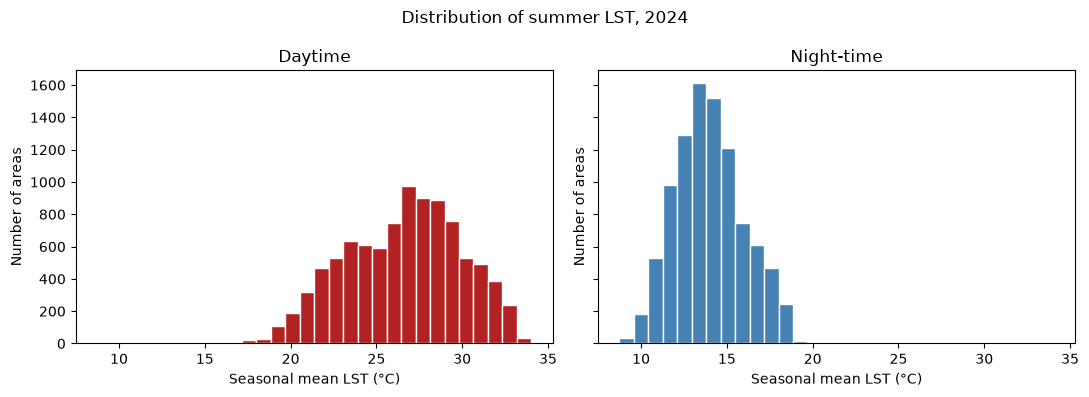

In [6]:
bins = np.linspace(
    min(day_values.min(), night_values.min()),
    max(day_values.max(), night_values.max()),
    31
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4),
                         sharex=True, sharey=True)

for ax, values, label, color in zip(
    axes,
    [day_values, night_values],
    ["Daytime", "Night-time"],
    ["firebrick", "steelblue"]
):
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set(
        title=label,
        xlabel="Seasonal mean LST (°C)",
        ylabel="Number of areas"
    )

fig.suptitle(f"Distribution of summer LST, {year}")
plt.tight_layout()
plt.show()

> **Note:** The daytime LST distribution is broader, with 
> the highest concentration of areas around 27–29°C. 
> Night-time LST is more concentrated around 13–15°C, 
> indicating less spatial variability. The common temperature 
> scale allows direct comparison of the two distributions. 
> However, these distributions do not represent cooling rates 
> or matched day–night temperature differences.

## 4. Visualising the Dataset

### Mapping Summer Daytime and Night-time LST

The following maps show the spatial distribution of seasonal mean 
daytime and night-time LST across the UK. Both maps use a common 
colour scale to allow direct comparison. Grey areas indicate 
missing or non-finite values.

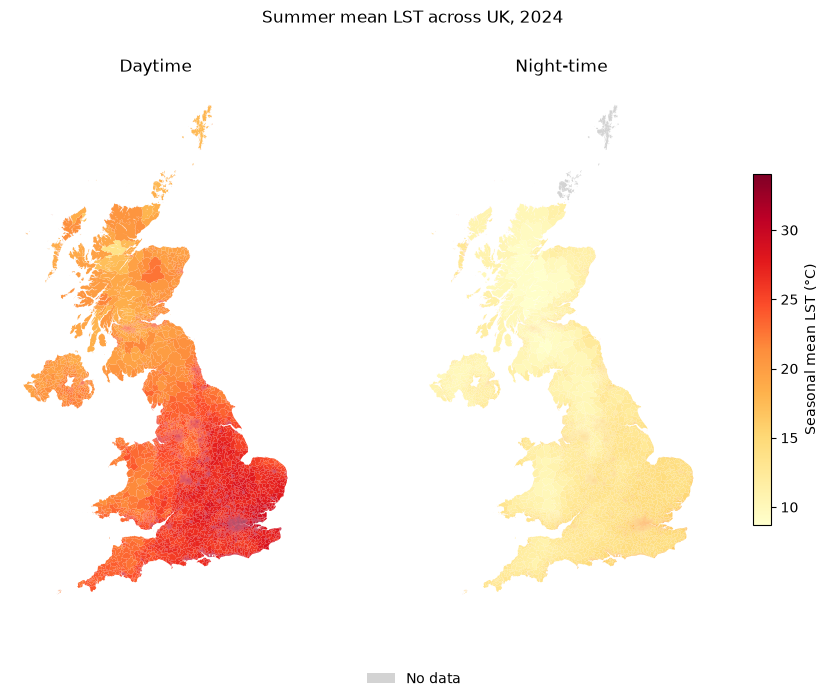

In [8]:
vmin = min(day_values.min(), night_values.min())
vmax = max(day_values.max(), night_values.max())
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, frame, indicator, label in [(axes[0], day, day_indicator, "Daytime"),
                                    (axes[1], night, night_indicator, "Night-time")]:
    plot_frame = frame.to_crs(27700).copy()
    plot_frame[indicator] = plot_frame[indicator].replace([np.inf, -np.inf], np.nan)
    plot_frame.plot(column=indicator, ax=ax, cmap="YlOrRd", vmin=vmin, vmax=vmax,
                    linewidth=0, missing_kwds={"color": "lightgrey"})
    ax.set_title(label)
    ax.set_axis_off()
sm = plt.cm.ScalarMappable(norm=plt.Normalize(vmin, vmax), cmap="YlOrRd")
fig.colorbar(sm, ax=axes, shrink=0.65, label="Seasonal mean LST (°C)")
fig.suptitle(f"Summer mean LST across UK, {year}")
from matplotlib.patches import Patch

fig.legend(
    handles=[Patch(facecolor="lightgrey", label="No data")],
    loc="lower center",
    frameon=False
)
plt.show()

> **Note:** Daytime land surface temperatures are generally
> higher across southern and eastern England, while cooler
> conditions are observed across northern and western regions.
> Night-time temperatures are substantially lower, with less
> pronounced spatial variation on the shared temperature scale.
> Using a common colour scale allows direct comparison of
> absolute temperatures between daytime and night-time conditions.
> Differences in valid observation coverage should also be
> considered when interpreting these spatial patterns.

## What have we learnt?

We have loaded and inspected Sentinel-3 LST indicators, compared daytime and night-time distributions using consistent scales, and calculated a two-year difference for matched statistical areas. The workflow can be adapted to other available years and indicators after checking their definitions and coverage.

Further research could investigate relationships with greenspace, built surfaces or population characteristics, or examine longer time series. These questions are left open for participants.

## References and further reading

- [IMAGO Data Catalogue](https://data.imago.ac.uk/) — product metadata, indicator definitions, units and processing methodology.

- Ghent, D., Veal, K., and Perry, M. (2025).
  [EOCIS: Daily Land Surface Temperature from Sentinel-3B SLSTR, Level 3 Collated (L3C) Global Product, Version 4.00](https://doi.org/10.5285/fc0bc3d5887d441296091a8025f8f45d).
  NERC EDS Centre for Environmental Data Analysis (CEDA).

- Ghent, D. J., Anand, J. S., Veal, K., and Remedios, J. J. (2024).
  [The Operational and Climate Land Surface Temperature Products from the Sea and Land Surface Temperature Radiometers on Sentinel-3A and 3B](https://doi.org/10.3390/rs16183403).
  Remote Sensing, 16(18), 3403.

- [Copernicus Sentinel-3 mission](https://sentinels.copernicus.eu/web/sentinel/missions/sentinel-3) — mission and instrument background.

- [EOCIS](https://eocis.org/) — Earth Observation Climate Information Service.
